## The Familiarity Principle

Let's say we're data journalists, and we're working on an article about the coronavirus. Our goal is to make readers more aware of how devastating this virus is — the assumption is that we're writing the article in December 2020, when the coronavirus was still fairly new.

Although unpleasant, we want to make readers more aware that people are dying because of this virus. To that end, we want to include a graph in the article that shows the top 20 countries by the number of deaths.

We've already collected the data and added it in the top20_deathtoll.csv file (the data was collected from Worldometer on December 8, 2020): https://www.worldometers.info/

In [1]:
import pandas as pd
top20_deathtoll = pd.read_csv('top20_deathtoll.csv')
print(top20_deathtoll)

   Country_Other  Total_Deaths
0         Turkey       15103.0
1          Chile       15663.0
2        Belgium       17386.0
3      Indonesia       18000.0
4        Germany       19539.0
5         Poland       20592.0
6   South Africa       22249.0
7           Peru       36324.0
8       Colombia       37995.0
9      Argentina       39888.0
10        Russia       44159.0
11         Spain       46646.0
12          Iran       50917.0
13        France       55521.0
14         Italy       60606.0
15            UK       61434.0
16        Mexico      110074.0
17         India      141005.0
18        Brazil      177388.0
19           USA      290798.0


First, we need to decide which type of graph to use. To make a good decision, we need to choose a graph that our audience can easily understand.

Ease of understanding often comes from familiarity. If people already know how to read a bar plot, they can immediately start reading the data on the graph. If they aren't familiar with a bar plot, they first need to figure out how to read one.

The ` familiarity principle ` typically favors simple graphs over complicated, eye-catching graphs. As data scientists,` we use visuals to communicate data correctly and efficiently.` Our primary aim is not to impress the audience on artistic grounds.

To display the top 20 countries by number of deaths, a horizontal bar plot should work well enough — let's assume our audience is familiar with this kind of graph.


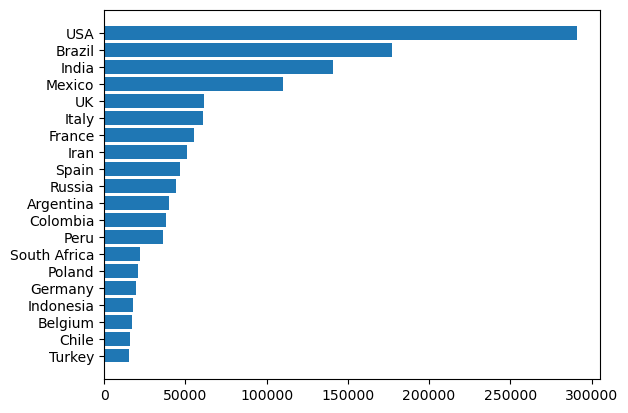

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

top20_deathtoll = pd.read_csv('top20_deathtoll.csv')
plt.barh(top20_deathtoll['Country_Other'], ## y-axis
         top20_deathtoll['Total_Deaths'])  ## x-axis
plt.show()

## Matplotlib Interfaces

To make the changes we want, we'll use matplotlib's ` object-oriented interface` Matplotlib has two interfaces:

- A functional interface: we use functions to create and modify plots.

- An object-oriented (OO) interface: we use methods to create and modify plots.

We used the` functional approach` when we called the function plt.barh(). We also used this approach extensively in the Data Visualization Fundamentals course when we created and modified graphs using functions from the matplotlib.pyplot submodule: ` plt.plot(), plt.scatter(), plt.title(), plt.xlim(), etc.`

The functional interface is simpler and easier to use. It comes in handy in the exploratory data visualization workflow, where we need to create graphs fast. But the ` OO interface ` offers more power and flexibility in graph editing.

## The OO Interface

To create a graph using the OO interface, we use the plt.subplots() function, which generates an empty plot and returns a tuple of two objects:

We assign the two objects inside the tuple to variables fig and ax:

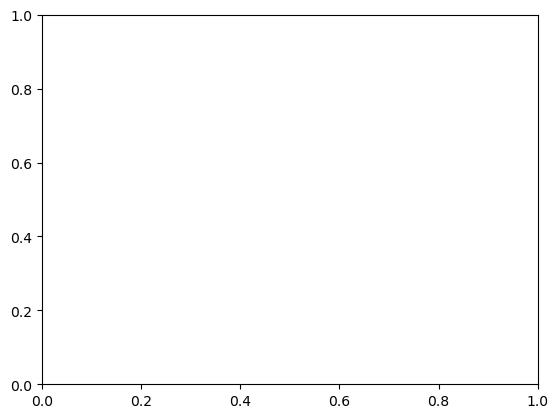

<class 'matplotlib.figure.Figure'>
<class 'matplotlib.axes._axes.Axes'>


In [3]:
fig, ax = plt.subplots()
plt.show()
print(type(fig))
print(type(ax))

The matplotlib.figure.Figure object acts as a canvas on which we can add one or more plots. The matplotlib.axes._subplots.AxesSubplot object is the actual plot. In short, we have two objects:

- The Figure (the canvas)
- The Axes (the plot; don't confuse with "axis," which is the x- and y-axis of a plot). 

To create a bar plot, we use the Axes.bar() method and call plt.show():

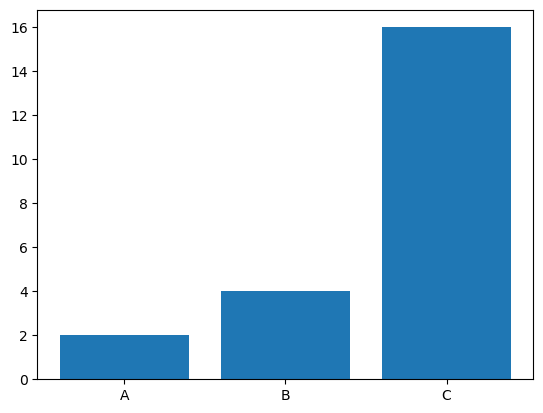

In [5]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])
plt.show()

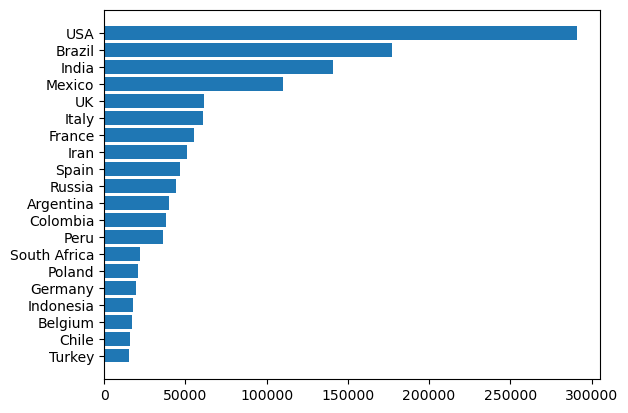

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

top20_deathtoll = pd.read_csv('top20_deathtoll.csv')


fig, ax = plt.subplots()
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'])
plt.show()

We know that a large part of our audience will read the article on a mobile device. This means our graph needs to `have mobile-friendly proportions: small width, larger height. Our graph currently has a small height and a larger width. `

To change the proportions, we can use the figsize parameter inside the  `plt.subplots(figsize=(width, height))` function:

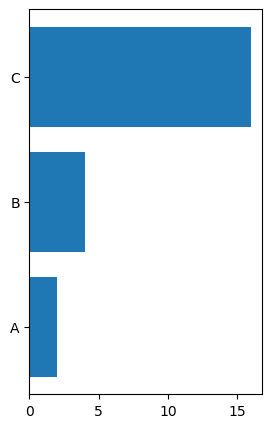

In [7]:
fig, ax = plt.subplots(figsize=(3, 5))
ax.barh(['A', 'B', 'C'],
        [2, 4, 16])
plt.show()

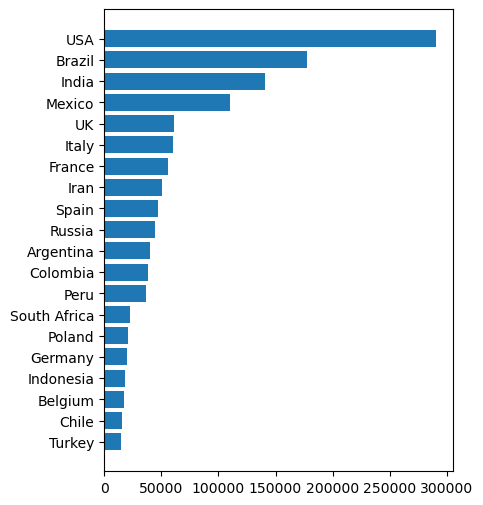

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'])
plt.show()

## Maximizing Data-Ink

When we design graphs (and anything in general), we need design principles to guide us. Design principles help us in two ways:

They generate design options.
They help us choose among those options.
One design principle we've already covered is familiarity. For example, if we need to visually present a frequency distribution, familiarity gives us a few options: a histogram and a box plot (let's assume our audience is only familiar with these two). Our audience, however, is more familiar with histograms, so we choose a histogram for our presentation.

The next design principle we're going to learn has to do with maximizing data elements on a graph. Generally, a graph has three elements:

- Data elements: the numbers and the categories visually represented and the relationships between them.
- Structural elements: the axes, the ticks, the legend, the grid, etc.
- Decorations: extra colors, shapes, artistic drawings etc.

Maximizing the data elements ensures the audience's attention is on the data — not on structure or decorations.

Edward Tufte theorized the principle of maximizing data elements in his book The Visual Display of Quantitative Information (1983). From the total amount of ink used for printing a graph, some of the ink goes to show the data — that is the data-ink. As a sidenote, Tufte worked on his book in the 1980s, when most graphs were printed on paper using ink.

Tufte named the principle of maximizing data elements as maximizing the data-ink ratio. The data-ink ratio is the proportion of data-ink from the total ink:

Data-ink ratio
=
data-ink
total ink used to print the graph
A graph with many decorations and structural parts has a low data-ink ratio. A graph where data-ink prevails has a greater data-ink ratio. Below, we see two theoretical examples:

Data-ink ratio
=
15
100
=
0.15
Data-ink ratio
=
75
100
=
0.75
We should try to maximize the data-ink ratio within reason. Some structural elements are necessary; otherwise, the graph can become unreadable. Decorations are optional by definition, but they can help prove a point in some cases. We'll continue this discussion on the next screen, where we'll modify our graph using Tufte's principle: maximizing the data-ink ratio.

## Erasing Non-Data Ink

To remove the axes (also called spines), we can use the Axes.spines[position].set_visible(bool) method, where position is a string indicating the location of the axis: 'left', 'right', 'top', and 'bottom'. For instance, this is how we remove the left and the bottom spines.

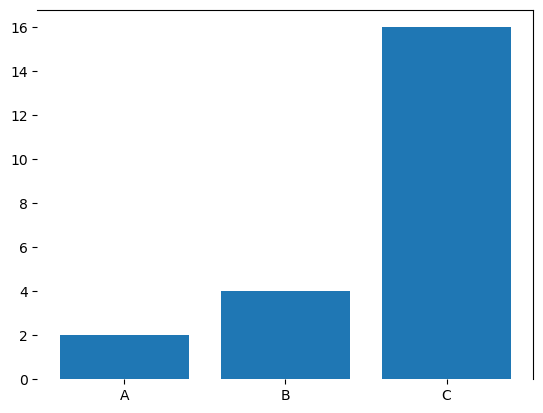

In [10]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.show()

If we want to remove all the spines, the fastest way is to use a for loop:

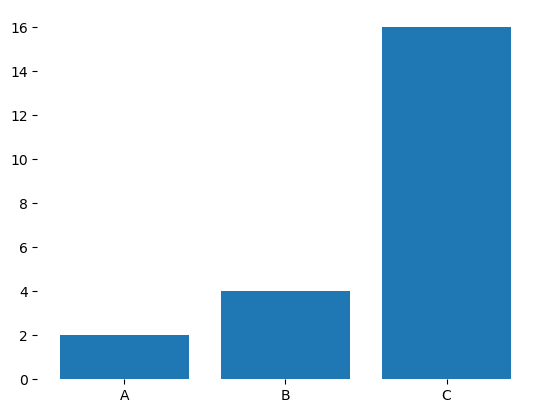

In [12]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)

plt.show()

To remove the ticks, we can use the Axes.tick_params(bottom, top, left, right) method. Below, we only need to remove the left and bottom ticks:

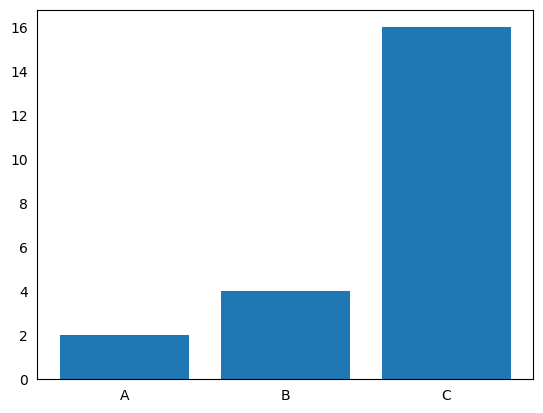

In [13]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])

ax.tick_params(bottom=False, left=False)
plt.show()

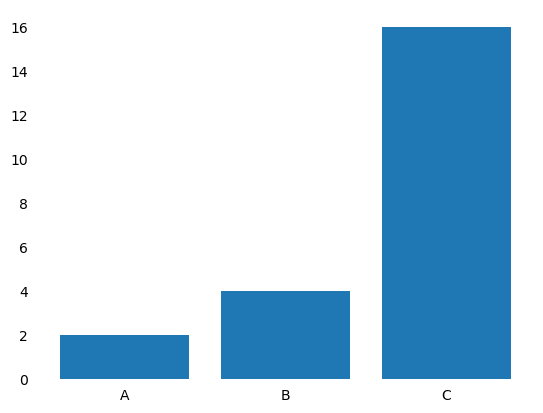

In [14]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
    
ax.tick_params(bottom=False, left=False)  

plt.show()

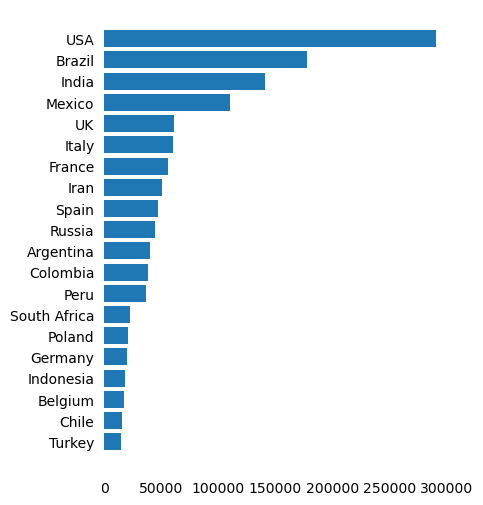

In [15]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'])

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
    
ax.tick_params(bottom=False, left=False) 

plt.show()

## Erasing Redundant Data-Ink 

On the previous screen, we erased some non-data ink from our graph. Another way to remove more ink is to erase redundant data-ink. For our horizontal bar plot, we can make the bars less thick and remove some of the x-tick labels (we can leave only the labels 0, 150000, and 300000).

To make the bars less thick, we can use the height parameter inside the Axes.barh() method. The height parameter has a `default value of 0.8.` Below, we exaggerate a little for the sake of the example and make the bars very thin, with height=0.1.

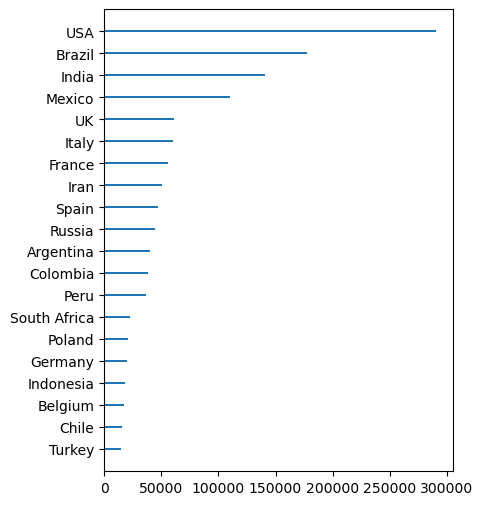

In [16]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'],
        height=0.1)
plt.show()

To remove some of the x-tick labels, we use the Axes.set_xticks method. Below, we only keep the labels 0, 100000, 200000, and 300000.

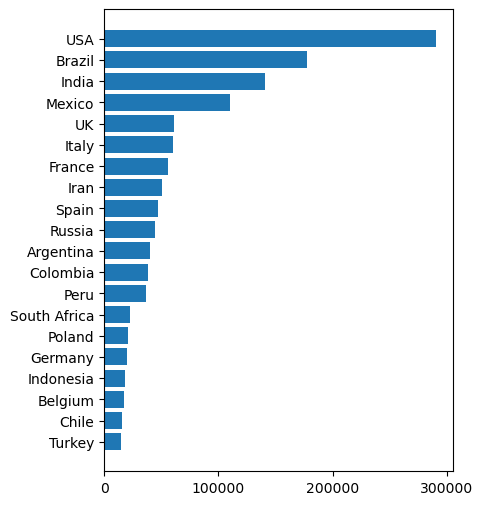

In [17]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'])
ax.set_xticks([0, 100000, 200000, 300000])
plt.show()

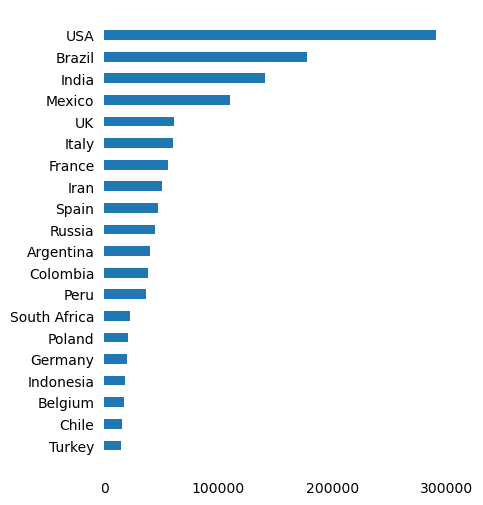

In [19]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'], 
        height=0.45)

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
ax.tick_params(bottom=False, left=False) 
ax.set_xticks([0, 100000, 200000, 300000])
plt.show()

## The Direction of Reading

So far in our lesson, we've applied two`design principles: `

- `We chose a horizontal bar graph using the familiarity principle.`

- `We modified the graph using the maximizing data-ink ratio principle. `

Another aspect that we need to consider is the `audience's direction of reading. ` As they scroll down through our article, they will read (and look at) our graph from top to bottom. More specifically, people usually start from top left and follow a zigzag pattern until they reach bottom right.

One problem with our graph is that the tick labels are located at the bottom. People will immediately see the country names, the bars, but they may get confused about the quantities.

To address that, we're going to move the tick labels at the top of the graph using the Axes.xaxis.tick_top() method:

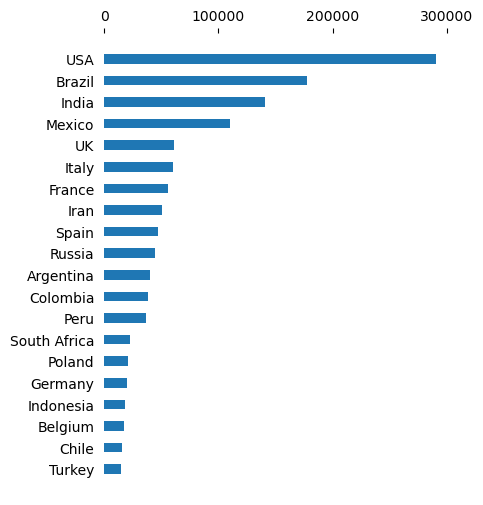

In [21]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'], 
        height=0.45)

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
ax.tick_params(bottom=False, left=False) 
ax.set_xticks([0, 100000, 200000, 300000])
ax.xaxis.tick_top()
plt.show()

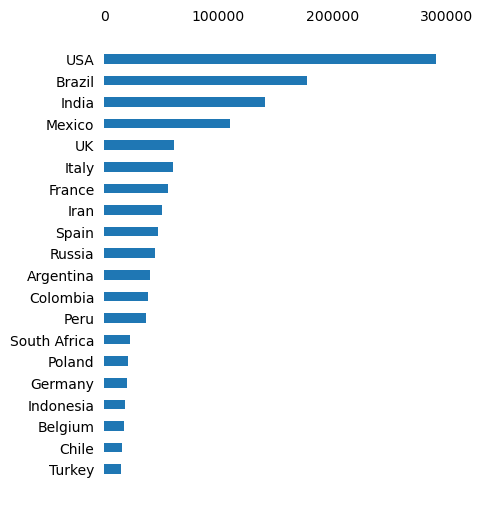

In [23]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'], 
        height=0.45)

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
ax.set_xticks([0, 100000, 200000, 300000])
ax.xaxis.tick_top()
ax.tick_params(top=False, left=False) # tick labels removed from top and left side
plt.show()

Right now, the first thing people will probably see are the x-tick labels. We want readers to focus on the data, so we'll do two things:

- We'll color the x-tick labels in grey so they don't stand out visually so much.
- We'll color the bars in a shade of red.

To color the x-tick labels, we use the same Axes.tick_params() method. However, we need to call it one more time because we only want to modify the ticks of the x-axis.

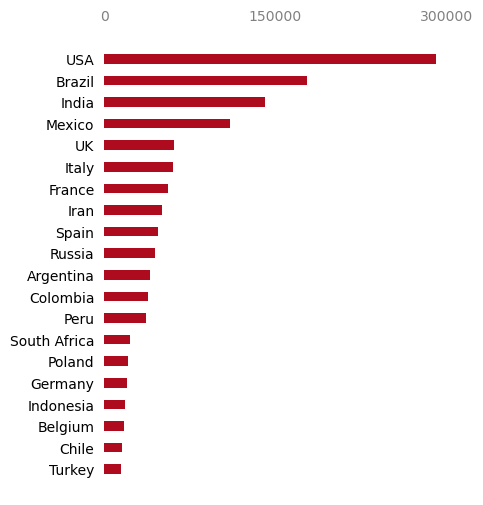

In [25]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'], 
        height=0.45, color='#af0b1e')    # changed colour using HEX values

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
    
ax.set_xticks([0, 150000, 300000])
ax.xaxis.tick_top()
ax.tick_params(top=False, left=False)
ax.tick_params(axis='x', colors='grey')   # changed colour x-axis 

plt.show()

## Title and Subtitle

To add a title and a subtitle, we're going to use the Axes.text() method. This method expects at least three arguments:

- x and y: the coordinates that give the position of the text.

- s: the text.

Below, we add a title and subtitle to a bar plot:

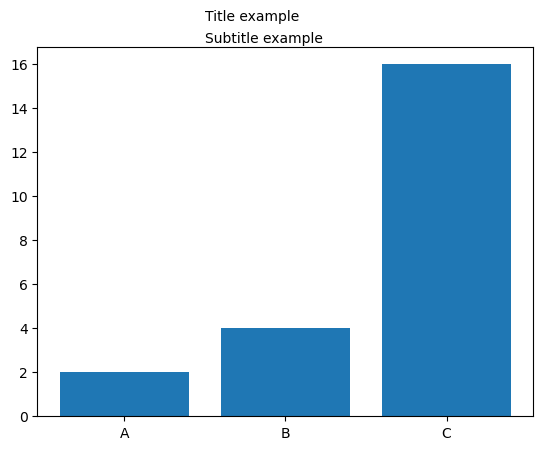

In [26]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])
ax.text(x=0.5, y=18, s='Title example') # this method has 3 arguments
ax.text(x=0.5, y=17, s='Subtitle example')
plt.show()

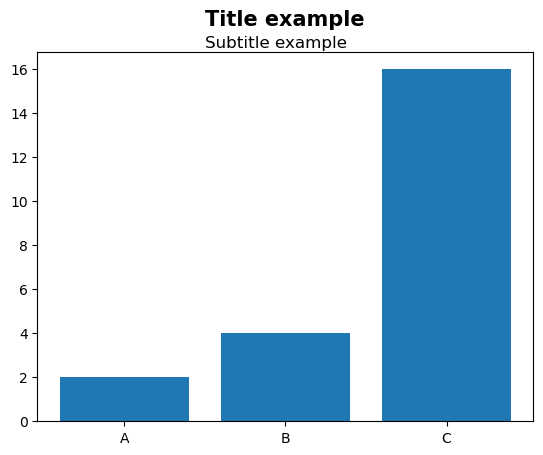

In [28]:
fig, ax = plt.subplots()
ax.bar(['A', 'B', 'C'],
       [2, 4, 16])
ax.text(x=0.5, y=18, s='Title example',
        size=15, weight='bold')  # this method has a size and weight parameter
ax.text(x=0.5, y=17, s='Subtitle example',
        size=12)
plt.show()

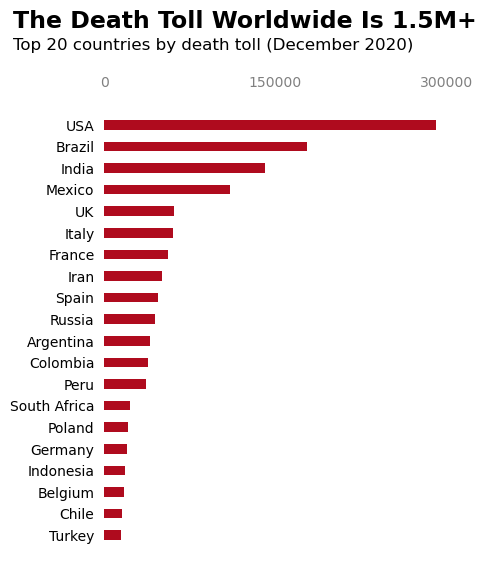

In [31]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'], 
        height=0.45, color='#af0b1e')   

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
    
ax.set_xticks([0, 150000, 300000])
ax.xaxis.tick_top()
ax.tick_params(top=False, left=False)
ax.tick_params(axis='x', colors='grey')  


ax.text(x=-80000, y=23.5,
        s='The Death Toll Worldwide Is 1.5M+',
        weight='bold', size=17)
ax.text(x=-80000, y=22.5,
        s='Top 20 countries by death toll (December 2020)',
        size=12)

plt.show()



## Final Touches

Next, we're only going to give it some final touches. First, we'll make the y-tick labels easier to read. We'll add a comma to both 150000 and 300000 to make them more readable — so people don't have to struggle to tell whether it's a 30,000 or a 300,000, for instance.

To make this change, we use the Axes.set_xticklabels() method.

Next, we're going to left-align the y-tick labels (the country names) by applying a for loop over the country names using python's zip function. Thereafter, we will leverage the flexibility of matplotlib's Axes.text() method. First, however, we're going to remove the current labels using the Axes.set_yticklabels() method.

In [32]:
# Assume the rest of the code is written
ax.set_yticklabels([]) # an empty list removes the labels
country_names = top20_deathtoll['Country_Other']
for i, country in zip(range(20), country_names):
    ax.text(x=-80000, y=i-0.15, s=country)
    

The color of the vertical line is too bright and stands out more than we want. Moreover, the line spans too far vertically and isn't on the same line with the Turkey label. To fix these problems, we're going to use the following:

- The ymin parameter to make it shorter — where 0 is the bottom of the plot, and 1 is the top of the plot.
- The c parameter to change the color to 'grey'.
- The alpha parameter to add transparency to the line.

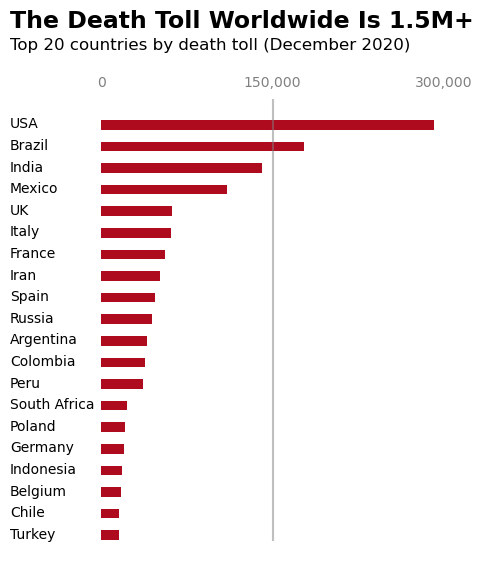

In [35]:
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.barh(top20_deathtoll['Country_Other'],
        top20_deathtoll['Total_Deaths'], 
        height=0.45, color='#af0b1e')   

for location in ['left', 'right', 'bottom', 'top']:
    ax.spines[location].set_visible(False)
    
ax.set_xticks([0, 150000, 300000])
ax.xaxis.tick_top()
ax.tick_params(top=False, left=False)
ax.tick_params(axis='x', colors='grey')  


ax.text(x=-80000, y=23.5,
        s='The Death Toll Worldwide Is 1.5M+',
        weight='bold', size=17)
ax.text(x=-80000, y=22.5,
        s='Top 20 countries by death toll (December 2020)',
        size=12)

ax.set_xticklabels(['0', '150,000', '300,000'])

ax.set_yticklabels([])
country_names = top20_deathtoll['Country_Other']
for i, country in zip(range(20), country_names):
    ax.text(x=-80000, y=i-0.15, s=country)
    
ax.axvline(x=150000, ymin=0.045, c='grey', alpha=0.5)

plt.show()

## Data Stories

According to some, what we did is storytelling with data. However, is presenting the top 20 countries according to death toll really a story?

In a broad sense, a story is a sequence of events: something happens, then something else happens, and so on. Rather than events, our graph above presents facts.

Another story element is change: something or someone changes throughout the story. Our graph is static: the information we present doesn't show any element of change.

There's nothing wrong with showing facts or presenting static information, but that's not a story. To create a data story, we need to wrap those numerical facts into events that show change.

For our example above, we can take the particular case of the United States and show how the death toll has changed since the beginning of the pandemic. Below, we see an example of a data story:


## Grid Charts in Matplotlib

We'll learn how to recreate this graph throughout this lesson. We begin with creating a grid chart of four rows by one column using the plt.subplots() function. 

We also adjust the figure size to (6, 8) since we want to keep a mobile-friendly ratio.

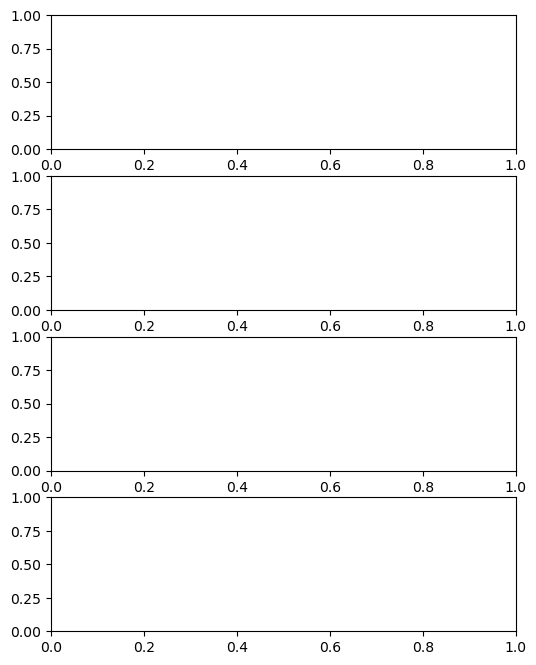

In [36]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))
plt.show()

The function returns two objects: a Figure and an array of four Axes objects. We use (ax1, ax2, ax3, ax4) to assign each object within that array to a different variable.

To draw on the individual plots, we can use Matplotlib methods on each of the four Axes objects. Below, we draw a line plot on the first and the third plot

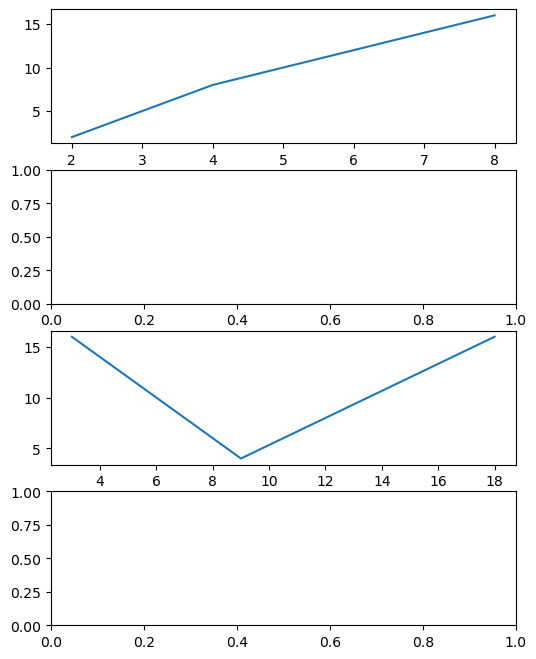

In [37]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))
ax1.plot([2, 4, 8], [2, 8, 16])
ax3.plot([3, 9, 18], [16, 4, 16])
plt.show()

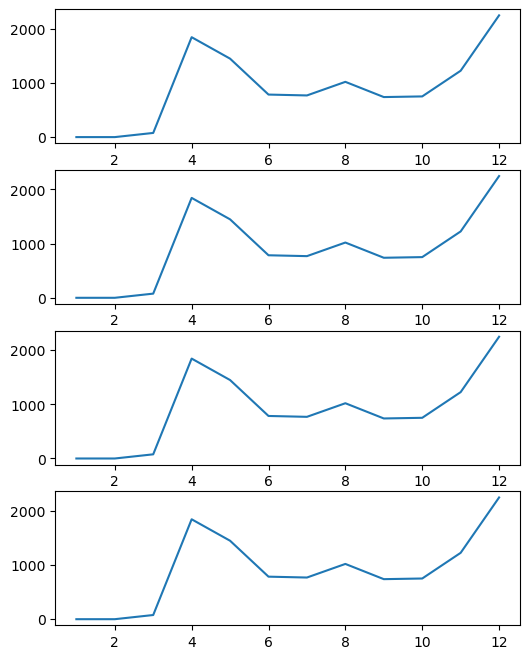

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

death_toll = pd.read_csv('covid_avg_deaths.csv')

fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

ax1.plot(death_toll['Month'], death_toll['New_deaths'])
ax2.plot(death_toll['Month'], death_toll['New_deaths'])
ax3.plot(death_toll['Month'], death_toll['New_deaths'])
ax4.plot(death_toll['Month'], death_toll['New_deaths'])

plt.show()



## Faster Workflow with for lopp command

Since we draw the same plot on each of the four Axes objects, we can simplify our work using a for loop. First, we group the four Axes objects into a Python list, and then we iterate over that list:

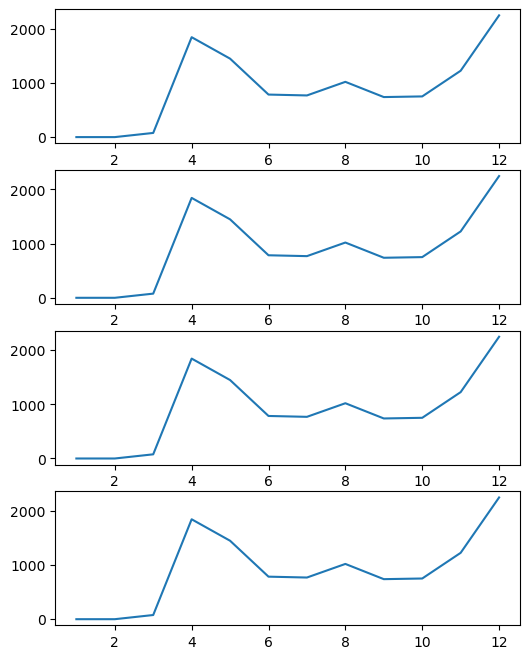

In [40]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4] # create a list with four axes 
for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'])
    
plt.show()

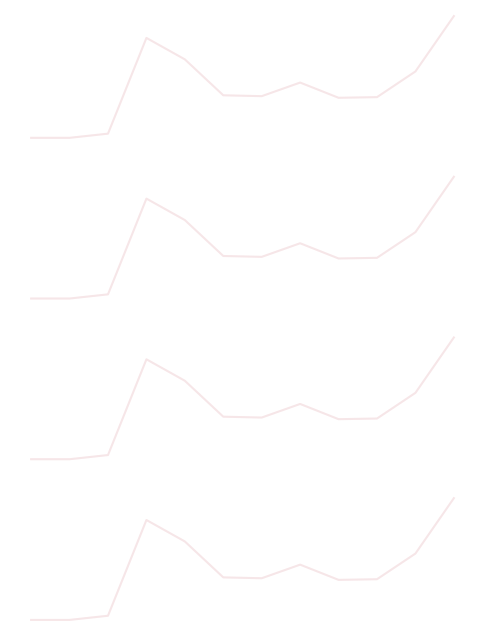

In [48]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)   
    ax.spines['top'].set_visible(False)        
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.show()

Matplotlib can be very powerful if you're a little imaginative. You'll often want to make a specific change and search for a function that will specifically handle that change. This approach won't always work because the function you want may not exist.

However, it'll often be possible to get what you want by combining what Matplotlib already has. To do that, identify the basic parts of what you want to create. Then, try to create those basic parts using Matplotlib.

Let's now highlight the last two periods: June–October and October–December. We've already added the code for the first two.

Now, we draw separate line plots on top of the current ones. We begin by drawing the first one — we use the same color and increase the line width using the linewidth parameter.

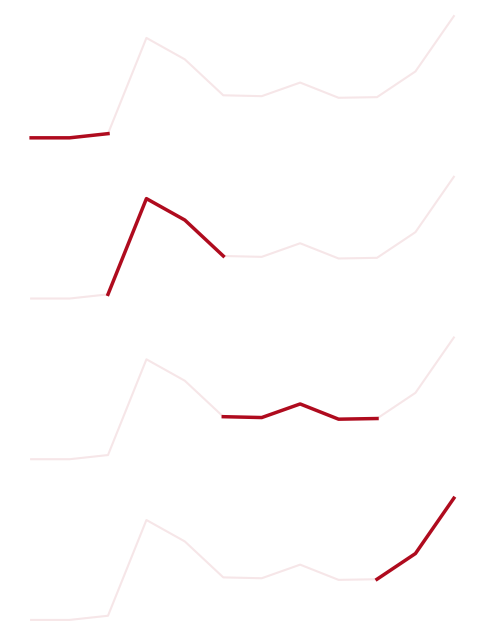

In [52]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

plt.show()

## Adding Structural Elements

First, we're going to show the quantities by adding three labels on the first plot — we do this using the Axis.text() method. We arrived at the exact x- and y-coordinates you see below through a process of trial and error.

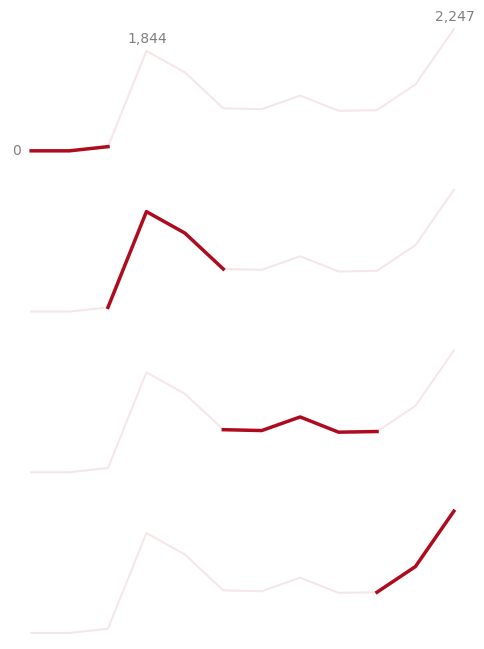

In [53]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

ax1.text(0.5, -80, '0', alpha=0.5)      #adding labels
ax1.text(3.5, 2000, '1,844', alpha=0.5)
ax1.text(11.5, 2400, '2,247', alpha=0.5)


plt.show()

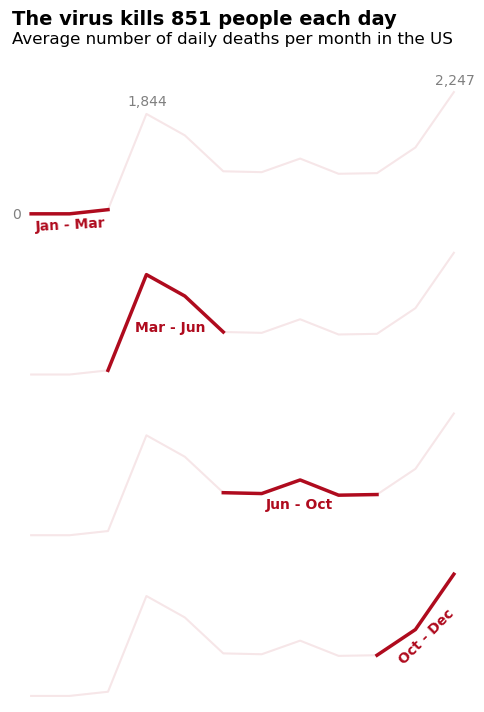

In [59]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

ax1.text(0.5, -80, '0', alpha=0.5)      #adding labels
ax1.text(3.5, 2000, '1,844', alpha=0.5)
ax1.text(11.5, 2400, '2,247', alpha=0.5)

ax1.text(1.1, -300, 'Jan - Mar', color='#af0b1e',    #label the highlighted periods
         weight='bold', rotation=3)
ax2.text(3.7, 800, 'Mar - Jun', color='#af0b1e',
         weight='bold')
ax3.text(7.1, 500, 'Jun - Oct', color='#af0b1e',
         weight='bold')
ax4.text(10.5, 600, 'Oct - Dec', color='#af0b1e',
         weight='bold', rotation=45)

ax1.text(x=0.5, y=3500,                          # add title to axes 1 (ax.1.text)
        s='The virus kills 851 people each day',
        weight='bold', size=14)
ax1.text(x=0.5, y=3150,                          # add subtitle to axes 1 (ax.1.text)
        s='Average number of daily deaths per month in the US',
        size=12)

plt.show()

## Adding a progress bar

We don't have a Matplotlib function specifically built for creating progress bars. Our approach, however, is to do the following:

Determine the basic parts of a progress bar.
Use Matplotlib to create those parts.
A progress bar is made of two rectangles. The rectangles are different colors, and the one with a darker shade is put on top of the other — this creates a visual sense of progress.

To create a rectangle in Matplotlib, we can draw a thick horizontal line. To draw a horizontal line, we can use the Axes.axhline() method. The y parameter specifies the y-coordinate of the horizontal line.

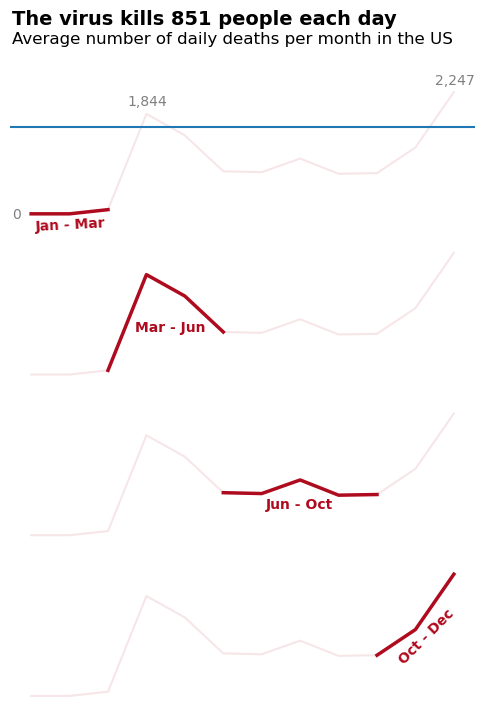

In [60]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

ax1.text(0.5, -80, '0', alpha=0.5)      #adding labels
ax1.text(3.5, 2000, '1,844', alpha=0.5)
ax1.text(11.5, 2400, '2,247', alpha=0.5)

ax1.text(1.1, -300, 'Jan - Mar', color='#af0b1e',    #label the highlighted periods
         weight='bold', rotation=3)
ax2.text(3.7, 800, 'Mar - Jun', color='#af0b1e',
         weight='bold')
ax3.text(7.1, 500, 'Jun - Oct', color='#af0b1e',
         weight='bold')
ax4.text(10.5, 600, 'Oct - Dec', color='#af0b1e',
         weight='bold', rotation=45)

ax1.text(x=0.5, y=3500,                          # add title to axes 1 (ax.1.text)
        s='The virus kills 851 people each day',
        weight='bold', size=14)
ax1.text(x=0.5, y=3150,                          # add subtitle to axes 1 (ax.1.text)
        s='Average number of daily deaths per month in the US',
        size=12)

ax1.axhline(y=1600)    #progress bar

plt.show()

Now that we have drawn a horizontal line, we need to do the following:

- Make the line shorter — we control the line's length using xmin and xmax parameters.
- Increase the line's width to make it look like a rectangle — we use the linewidth parameter.
- Change the color to '#af0b1e' and increase its transparency — we use the color and alpha parameters.

## Creating 100 Percent Progress bar

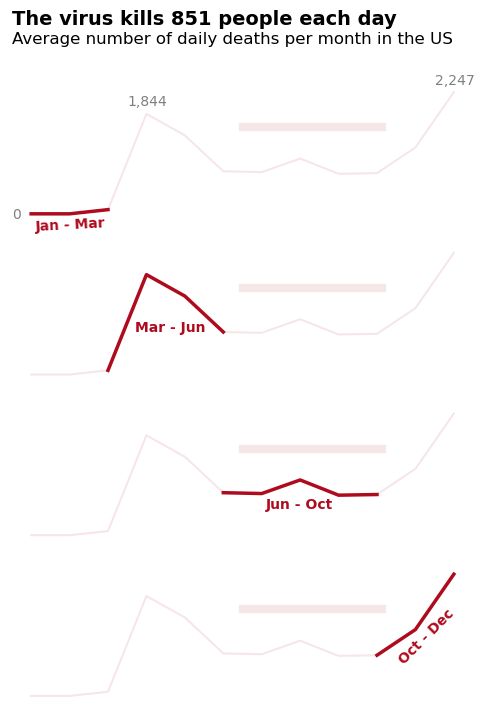

In [62]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

ax1.text(0.5, -80, '0', alpha=0.5)      #adding labels
ax1.text(3.5, 2000, '1,844', alpha=0.5)
ax1.text(11.5, 2400, '2,247', alpha=0.5)

ax1.text(1.1, -300, 'Jan - Mar', color='#af0b1e',    #label the highlighted periods
         weight='bold', rotation=3)
ax2.text(3.7, 800, 'Mar - Jun', color='#af0b1e',
         weight='bold')
ax3.text(7.1, 500, 'Jun - Oct', color='#af0b1e',
         weight='bold')
ax4.text(10.5, 600, 'Oct - Dec', color='#af0b1e',
         weight='bold', rotation=45)

ax1.text(x=0.5, y=3500,                          # add title to axes 1 (ax.1.text)
        s='The virus kills 851 people each day',
        weight='bold', size=14)
ax1.text(x=0.5, y=3150,                          # add subtitle to axes 1 (ax.1.text)
        s='Average number of daily deaths per month in the US',
        size=12)

#creating progress bar

ax1.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax2.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax3.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax4.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)

plt.show()

## Calculating Proportions for cumulative death bar

In [63]:
deaths = [2387, 126203, 227178, 295406]
proportions = [round(death/295406, 2) for death in deaths]
xmax_vals = [round(0.5 + proportion * 0.3, 3) for proportion in proportions]
print(proportions)
print(xmax_vals)

[0.01, 0.43, 0.77, 1.0]
[0.503, 0.629, 0.731, 0.8]


The progress bars all indicate the same quantity, so we need to modify them as a function of the cumulative number of deaths. Inside the code block below, we see three lists:

- deaths: the number of cumulative deaths at the end of March, June, October, and December (note: we collected the December data on December 15th).

- proportions: the proportion of deaths for each of those months relative to the current death toll (December 15th).

- xmax_vals: the values we'll need to use for the xmax parameter of Axes.axhline() to control its length. We multiplied each proportion by 0.3 because xmax - xmin = 0.8 - 0.5 = 0.3.


Explain this code: The code above defines two lists: "deaths" and "proportions". 

The "deaths" list contains four values representing the number of deaths from a certain disease in different time periods. 

The "proportions" list is calculated by dividing each value in the "deaths" list by the total number of deaths (295406) 
and rounding the result to two decimal places.

The code then calculates a new list called "xmax_vals" by multiplying each value in the "proportions" list by 0.3 and adding 0.5 to it. This calculation is intended to be used as the maximum value for a horizontal bar chart. The resulting values are rounded to three decimal places.

Overall, the code is performing some basic data manipulation and calculations to prepare the data for visualization in a horizontal bar chart.

## Adding cumulative death bar on top

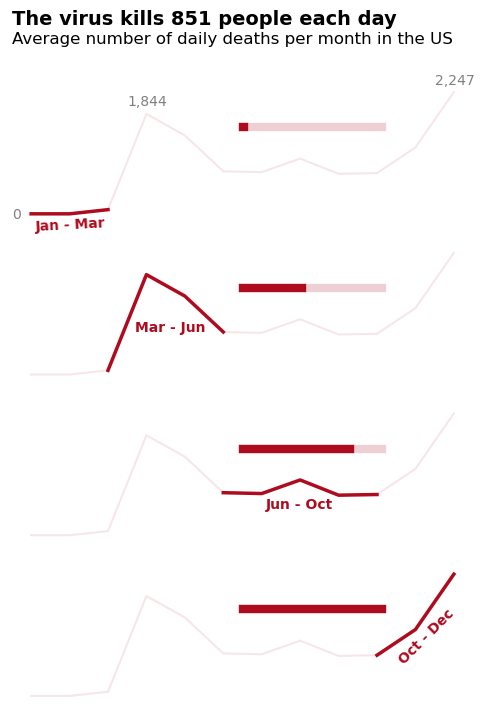

In [64]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

ax1.text(0.5, -80, '0', alpha=0.5)      #adding labels
ax1.text(3.5, 2000, '1,844', alpha=0.5)
ax1.text(11.5, 2400, '2,247', alpha=0.5)

ax1.text(1.1, -300, 'Jan - Mar', color='#af0b1e',    #label the highlighted periods
         weight='bold', rotation=3)
ax2.text(3.7, 800, 'Mar - Jun', color='#af0b1e',
         weight='bold')
ax3.text(7.1, 500, 'Jun - Oct', color='#af0b1e',
         weight='bold')
ax4.text(10.5, 600, 'Oct - Dec', color='#af0b1e',
         weight='bold', rotation=45)

ax1.text(x=0.5, y=3500,                          # add title to axes 1 (ax.1.text)
        s='The virus kills 851 people each day',
        weight='bold', size=14)
ax1.text(x=0.5, y=3150,                          # add subtitle to axes 1 (ax.1.text)
        s='Average number of daily deaths per month in the US',
        size=12)

ax1.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax2.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax3.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax4.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)

#completing progress bar
for ax, xmax in zip(axes, xmax_vals):    
    ax.axhline(y=1600, xmin=0.5, xmax=0.8,
               linewidth=6, color='#af0b1e', alpha=0.1)
    ax.axhline(y=1600, xmin=0.5, xmax=xmax,
               linewidth=6, color='#af0b1e')

plt.show()

## Adding labels to bar

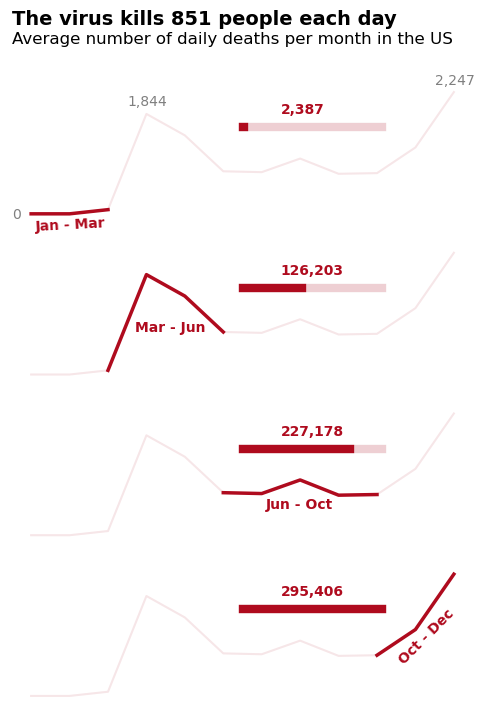

In [72]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(nrows=4, ncols=1,
                                         figsize=(6,8))

axes = [ax1, ax2, ax3, ax4]

for ax in axes: 
    ax.plot(death_toll['Month'],
death_toll['New_deaths'],
           color='#af0b1e', alpha=0.1)        # colour and transparency of lines
    ax.set_yticklabels([])                    
    ax.set_xticklabels([])
    ax.tick_params(bottom=False, left=False)
    for location in ['left', 'right', 'top', 'bottom']:    #for loop command within for loop
        ax.spines[location].set_visible(False)
        
ax1.plot(death_toll['Month'][:3], death_toll['New_deaths'][:3],
         color='#af0b1e', linewidth=2.5)
ax2.plot(death_toll['Month'][2:6], death_toll['New_deaths'][2:6],   #march-june
         color='#af0b1e', linewidth=2.5)
ax3.plot(death_toll['Month'][5:10], death_toll['New_deaths'][5:10],   #june-october
         color='#af0b1e', linewidth=2.5)
ax4.plot(death_toll['Month'][9:12], death_toll['New_deaths'][9:12],    #october-december
         color='#af0b1e', linewidth=2.5)

ax1.text(0.5, -80, '0', alpha=0.5)      #adding labels
ax1.text(3.5, 2000, '1,844', alpha=0.5)
ax1.text(11.5, 2400, '2,247', alpha=0.5)

ax1.text(1.1, -300, 'Jan - Mar', color='#af0b1e',    #label the highlighted periods
         weight='bold', rotation=3)
ax2.text(3.7, 800, 'Mar - Jun', color='#af0b1e',
         weight='bold')
ax3.text(7.1, 500, 'Jun - Oct', color='#af0b1e',
         weight='bold')
ax4.text(10.5, 600, 'Oct - Dec', color='#af0b1e',
         weight='bold', rotation=45)

ax1.text(x=0.5, y=3500,                          # add title to axes 1 (ax.1.text)
        s='The virus kills 851 people each day',
        weight='bold', size=14)
ax1.text(x=0.5, y=3150,                          # add subtitle to axes 1 (ax.1.text)
        s='Average number of daily deaths per month in the US',
        size=12)

#creating Progress bar

ax1.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax2.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax3.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)
ax4.axhline(y=1600, xmin=0.5, xmax=0.8,
           linewidth=6, color='#af0b1e', alpha=0.1)

#completing progress bar with additional line of code
for ax, xmax, death in zip(axes, xmax_vals, deaths):
    ax.axhline(y=1600, xmin=0.5, xmax=0.8,
               linewidth=6, color='#af0b1e',
               alpha=0.1)
    ax.axhline(y=1600, xmin=0.5, xmax=xmax,
               linewidth=6, color='#af0b1e')
    ax.text(7.5, 1850, format(death, ','),  #added line
            color='#af0b1e', weight='bold')

plt.show()